In [3]:
atomic_numbers = {
    'H': 1,
    'He': 2,
    'Li': 3,
    'Be': 4,
    'B': 5,
    'C': 6,
    'N': 7,
    'O': 8,
    'F': 9,
    'Ne': 10,
    'Na': 11,
    'Mg': 12,
    'Al': 13,
    'Si': 14,
    'P': 15,
    'S': 16,
    'Cl': 17,
    'Ar': 18,
    'K': 19,
    'Ca': 20,
    'Sc': 21,
    'Ti': 22,
    'V': 23,
    'Cr': 24,
    'Mn': 25,
    'Fe': 26,
    'Ni': 28,
    'Co': 27,
    'Cu': 29,
    'Zn': 30,
    'Ga': 31,
    'Ge': 32,
    'As': 33,
    'Se': 34,
    'Br': 35,
    'Kr': 36,
    'Rb': 37,
    'Sr': 38,
    'Y': 39,
    'Zr': 40,
    'Nb': 41,
    'Mo': 42,
    'Tc': 43,
    'Ru': 44,
    'Rh': 45,
    'Pd': 46,
    'Ag': 47,
    'Cd': 48,
    'In': 49,
    'Sn': 50,
    'Sb': 51,
    'I': 53,
    'Te': 52,
    'Xe': 54,
    'Cs': 55,
    'Ba': 56,
    'La': 57,
    'Ce': 58,
    'Pr': 59,
    'Nd': 60,
    'Pm': 61,
    'Sm': 62,
    'Eu': 63,
    'Gd': 64,
    'Tb': 65,
    'Dy': 66,
    'Ho': 67,
    'Er': 68,
    'Tm': 69,
    'Yb': 70,
    'Lu': 71,
    'Hf': 72,
    'Ta': 73,
    'W': 74,
    'Re': 75,
    'Os': 76,
    'Ir': 77,
    'Pt': 78,
    'Au': 79,
    'Hg': 80,
    'Tl': 81,
    'Pb': 82,
    'Bi': 83,
    'Po': 84,
    'At': 85,
    'Rn': 86,
    'Fr': 87,
    'Ra': 88,
    'Ac': 89,
    'Th': 90,
    'Pa': 91,
    'U': 92,
    'Np': 93,
    'Pu': 94,
    'Am': 95,
    'Cm': 96,
    'Bk': 97,
    'Cf': 98,
    'Es': 99,
    'Fm': 100,
    'Md': 101,
    'No': 102,
    'Lr': 103,
    'Rf': 104,
    'Db': 105,
    'Sg': 106,
    'Bh': 107,
    'Hs': 108,
    'Mt': 109,
    'Ds': 110,
    'Rg': 111,
    'Cn': 112,
    'Nh': 113,
    'Fl': 114,
    'Mc': 115,
    'Lv': 116,
    'Ts': 117,
    'Og': 118
}  

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Coordinate system conversions and supercell
def lat2cart(M,ionpos):
    return np.dot(ionpos,np.transpose(M))
        
def cart2lat(M,ionpos):
    return np.dot(ionpos,np.linalg.inv(np.transpose(M)))

def make_supercell(M,ionpos,ionspecies,nx,ny,nz):
    newM = np.dot( M,np.diag((nx,ny,nz)) )
    newIonpos = []
    newIonspecies = []
    for i in range(nx):
        fi = i/nx
        for j in range(ny):
            fj = j/ny
            for k in range(nz):
                fk = k/nz
                for v in ionpos:
                    newIonpos.append([(i+v[0])/nx,(j+v[1])/ny,(k+v[2])/nz])
                newIonspecies = np.concatenate((newIonspecies,ionspecies))
    return newM,newIonpos,newIonspecies

# return [a; b1, b2, ...]
def continuedFraction(a0,b):
    # Initialize numerator and denominator for the fractional part
    numerator, denominator = 0, 1  # Start with 0/1
    # Process the terms in reverse order
    for ai in reversed(b):
        numerator, denominator = denominator, ai * denominator + numerator
    # Add a0 to the result
    numerator, denominator = a0 * denominator + numerator, denominator
    return numerator, denominator
    
# Choose the Nth rational approximant to the sqrt(3) ratio
def getSqrt3RationalAppx(N):
    a0 = 1
    b = [ (i%2)+1 for i in range(N) ]
    return continuedFraction(a0,b)

# Write to an ionpos file
def writeIonposFile(ionpos,ionsp,fname):
    with open(fname,'w') as f:
        f.write("#Ionic Positions in Lattice Coordinates \n")
        for i in range(len(ionsp)):
            f.write("ion  "+ionsp[i]+" "+str(ionpos[i][0])+" "+str(ionpos[i][1])+" "+str(ionpos[i][2])+" 1 \n")
            
# Write to a lattice file, fname = "system.lattice" is typical
def writeLatticeFile(M, fname):
    with open(fname,'w') as f:
        f.write("lattice \ \n")
        for i in range(2):
            f.write(str(M[i][0])+"  "+str(M[i][1])+"  "+str(M[i][2])+" \ \n")
        f.write(str(M[2][0])+"  "+str(M[2][1])+"  "+str(M[2][2]))

# This only works for TBG for the moment
def writeIonspAuxFile(ionsp,fname):
    with open(fname,'w') as f:
        f.write("# Unique Ionsp Label, unitcell ionpos indx, isFlake \n")
        for sp in ionsp:
            if sp == 'C1':
                ucipindx = 0
                isFlake  = 0
            elif sp == 'C2':
                ucipindx = 1
                isFlake  = 0
            elif sp == 'C3':
                ucipindx = 0
                isFlake  = 1
            elif sp == 'C4':
                ucipindx = 1
                isFlake  = 1
            else:
                print("Unexected ionspecies encountered!!!")
            f.write(sp+"\t"+str(ucipindx)+"\t"+str(isFlake)+"\n")
            
Angstrom = 0.529177 # This many Angstroms per bohr
def writeXSF(M,ionpos,ionsp,fpath):
    M_Angstrom = M*Angstrom
    
    print("Writing to", fpath)
    with open(fpath,'w') as xsf_file:
        xsf_file.write("CRYSTAL \n")
        xsf_file.write("PRIMVEC \n")
        for i in range(3):
            xsf_file.write("  "+str(M_Angstrom.T[i][0])+"   "+str(M_Angstrom.T[i][1])+"   "+str(M_Angstrom.T[i][2])+" \n")
        xsf_file.write("PRIMCOORD \n")
        xsf_file.write(str(len(ionpos))+"   1 \n")
        ionpos_Angstrom = lat2cart(M_Angstrom,ionpos)
        for i in range(len(ionpos)):
            xsf_file.write(str(atomic_numbers[ionsp[i]])+"  "+str(ionpos_Angstrom[i][0])+"  "+str(ionpos_Angstrom[i][1])+"  "+str(ionpos_Angstrom[i][2]) + " \n" )     
        
###################################################################
path = "30DEG_TBG"
N = 4        # Decide which order of rational approximant of sqrt(3) to use
a = 4.6638441 # hexagonal graphene lattice constant
Lz = 25 # bohr    
il_dist = 6.577674 # bohr
###################################################################
z_flake = il_dist/Lz


# Find the numerator and denominator for the sqrt(3) approx
num, denom = getSqrt3RationalAppx(N)
print(num, denom)

R = num*a
print("R =", R)
a_flake = (R/denom)/np.sqrt(3)
print("a_flake/a =", a_flake/a, "is strained to make commensurate")

# Substrate ionpos and lattice
subs_ionsp   = np.array(["C1","C2","C1","C2"])
subs_ionpos  = np.array([[0.0,0.0,0.0],[0.5,1/6,0.0],[0.5,0.5,0.0],[0.0,2/3,0.0]])
subs_lattice = np.array([[a,0.0,0.0],[0.0,np.sqrt(3)*a,0.0],[0.0,0.0,Lz]])

# Flake ionpos and lattice strained to be exactly commensurate
flake_ionsp   = np.array(["C3","C4","C3","C4"]) # TODO: doublecheck convention
flake_ionpos  = np.array([[0.0,0.0,z_flake],[1/6,0.5,z_flake],[0.5,0.5,z_flake],[2/3,0.0,z_flake]])
flake_lattice = np.array([[np.sqrt(3)*a_flake,0.0,0.0],[0.0,a_flake,0.0],[0.0,0.0,Lz]])

# Make the supercell of the substrate (exact spacings)
subs_lattice_sc, subs_ionpos_sc, subs_ionsp_sc = make_supercell(subs_lattice,subs_ionpos,subs_ionsp,num,denom,1)
# Make the supercell of the flake (strained to commensurate)
flake_lattice_sc, flake_ionpos_sc, flake_ionsp_sc = make_supercell(flake_lattice,flake_ionpos,flake_ionsp,denom,num,1)

# Concatenate the substrate and flake layers together
commensurate_sc_ionpos  = np.concatenate((subs_ionpos_sc,flake_ionpos_sc))
commensurate_sc_ionsp   = np.concatenate((subs_ionsp_sc,flake_ionsp_sc))
commensurate_sc_lattice = subs_lattice_sc

# Save the large commensurate supercell to files
writeIonposFile(commensurate_sc_ionpos,commensurate_sc_ionsp,path+"/commensurate_small.ionpos")
writeLatticeFile(commensurate_sc_lattice,path+"/commensurate_small.lattice")
writeIonspAuxFile(commensurate_sc_ionsp,path+"/commensurate_small.aux")

# Also save an xsf for visualization purposes
# quick fix: remove last character of each ionsp to make them real atom names instead of e.g. C3
ionsp_xsf = [ sp[:-1] for sp in commensurate_sc_ionsp]

writeXSF(commensurate_sc_lattice,commensurate_sc_ionpos,ionsp_xsf,path+"/commensurate_small.xsf")

print("nAtoms =", len(commensurate_sc_ionpos))

print("DONE!")

19 11
R = 88.61303790000001
a_flake/a = 0.9972413740548082 is strained to make commensurate
Writing to 30DEG_TBG/commensurate_small.xsf
nAtoms = 1672
DONE!


[[88.6130379   0.          0.        ]
 [ 0.         88.85816434  0.        ]
 [ 0.          0.         25.        ]]


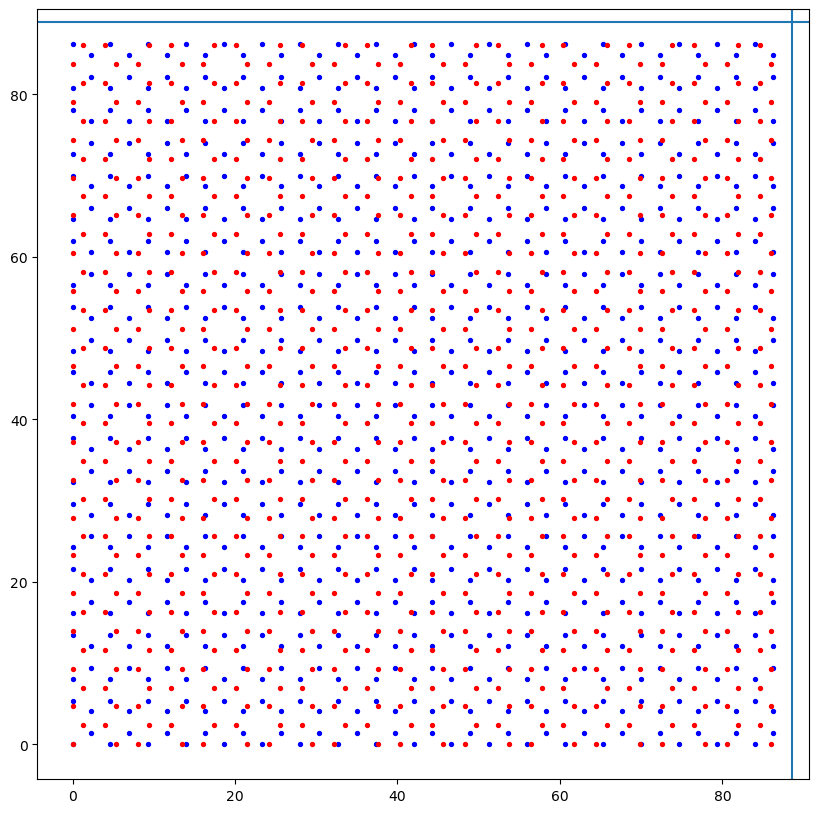

In [15]:
print(commensurate_sc_lattice)

# Plot in cartesian coordinates to visuzlize
subs_ionpos_cart = lat2cart(subs_lattice_sc, subs_ionpos_sc)
flake_ionpos_cart = lat2cart(flake_lattice_sc, flake_ionpos_sc)

plt.figure(figsize=(10,10))
plt.axes().set_aspect('equal')
plt.scatter(subs_ionpos_cart[:,0],subs_ionpos_cart[:,1],s=8,c='blue')
plt.scatter(flake_ionpos_cart[:,0],flake_ionpos_cart[:,1],s=8,c='red')
plt.axvline(commensurate_sc_lattice[0][0])
plt.axhline(commensurate_sc_lattice[1][1])
plt.show()

In [ ]:
# For the paper I want to display all of the interlayer registries

In [6]:
def continued_fraction_to_fraction(a0, b):
    """
    Converts a continued fraction representation (a0, b) into a fraction.
    
    Parameters:
        a0 (int): The integer part of the continued fraction.
        b (list): The list of coefficients [a1, a2, a3, ...].
    
    Returns:
        tuple: The resulting fraction as a tuple (numerator, denominator).
    """
    # Initialize numerator and denominator for the fractional part
    numerator, denominator = 0, 1  # Start with 0/1

    # Process the terms in reverse order
    for ai in reversed(b):
        numerator, denominator = denominator, ai * denominator + numerator
    
    # Add a0 to the result
    numerator, denominator = a0 * denominator + numerator, denominator
    
    return numerator, denominator

# Example usage
a0 = 0
b = [1, 4, 1, 5, 9]  # Corresponds to 1 + 1/(1 + 1/(2 + 1/1)) = 13/8
numerator, denominator = continued_fraction_to_fraction(a0, b)
print(f"{numerator}/{denominator}")  # Output: 13/8

266/321
